# Green Cellpose ΔF/F — session 216, run 04
Adapted from green_cellpose_suite2p_traces_and_plot_dff.ipynb for MY_71_R.
Run after Convert_seg_to_stat has completed for this run. Uses existing fluorescence and neuropil outputs, a 30-second rolling 20th-percentile baseline, and the original population-artifact detection/interpolation workflow. No registration or extraction is repeated.

Plots default to the first 2,000 frames; baseline and artifact calculations use the full recording. Percentile-scaled stacked plots show relative shape, not absolute ΔF/F amplitude. The final ROI dropdown shows unscaled ΔF/F. Outputs go into this run's cellpose_suite2p_sliding_dff subfolder; plane-level Suite2p files are not replaced.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import percentile_filter, binary_dilation


PLANE_DIR = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-04/suite2p/plane0')
# 'functional' loads F/Fneu; 'chan2' loads F_chan2/Fneu_chan2.
TRACE_SOURCE = 'functional'
OUTPUT_DIR = PLANE_DIR / 'cellpose_suite2p_sliding_dff'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

NEUROPIL_COEFFICIENT = 0.7
ops = np.load(PLANE_DIR / 'ops.npy', allow_pickle=True).item()
FRAME_RATE_HZ = float(ops['fs'])
if not np.isfinite(FRAME_RATE_HZ) or FRAME_RATE_HZ <= 0:
    raise ValueError('ops must contain a valid sampling rate in fs.')
BASELINE_WINDOW_SECONDS = 30.0
BASELINE_PERCENTILE = 20.0

if TRACE_SOURCE == 'functional':
    f_path, fneu_path = PLANE_DIR / 'F.npy', PLANE_DIR / 'Fneu.npy'
elif TRACE_SOURCE == 'chan2':
    f_path, fneu_path = PLANE_DIR / 'F_chan2.npy', PLANE_DIR / 'Fneu_chan2.npy'
else:
    raise ValueError("TRACE_SOURCE must be 'functional' or 'chan2'")

for path in [f_path, fneu_path, PLANE_DIR / 'stat.npy', PLANE_DIR / 'iscell.npy']:
    if not path.exists():
        raise FileNotFoundError(path)

print('Plane:', PLANE_DIR)
print('Trace source:', TRACE_SOURCE)
print('Output:', OUTPUT_DIR)

Plane: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-04/suite2p/plane0
Trace source: functional
Output: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-04/suite2p/plane0/cellpose_suite2p_sliding_dff


## Load converted Suite2p traces and calculate ΔF/F

In [2]:
F_cell = np.load(f_path).astype(np.float32)
F_neuropil = np.load(fneu_path).astype(np.float32)
stat = np.load(PLANE_DIR / 'stat.npy', allow_pickle=True)
iscell = np.load(PLANE_DIR / 'iscell.npy')

if F_cell.shape != F_neuropil.shape:
    raise ValueError(f'F shape {F_cell.shape} != Fneu shape {F_neuropil.shape}')
if F_cell.shape[0] != len(stat):
    raise ValueError(f'{F_cell.shape[0]} traces but {len(stat)} stat entries')

F_corrected = (F_cell - NEUROPIL_COEFFICIENT * F_neuropil).astype(np.float32)
window_frames = int(round(FRAME_RATE_HZ * BASELINE_WINDOW_SECONDS))
if window_frames < 1:
    raise ValueError('Baseline window must contain at least one frame')

F0_sliding = percentile_filter(
    F_corrected,
    percentile=BASELINE_PERCENTILE,
    size=(1, window_frames),
    mode='nearest',
)
valid_baseline = np.isfinite(F0_sliding) & (F0_sliding > 1e-6)
dff = np.full(F_corrected.shape, np.nan, dtype=np.float32)
np.divide(F_corrected - F0_sliding, F0_sliding, out=dff, where=valid_baseline)
valid_roi_indices = np.flatnonzero(np.any(np.isfinite(dff), axis=1))
invalid_roi_indices = np.setdiff1d(np.arange(dff.shape[0]), valid_roi_indices)

print('ROIs × frames:', dff.shape)
print(f'Baseline window: {window_frames} frames ({BASELINE_WINDOW_SECONDS:g} s)')
print(f'Valid ROIs: {len(valid_roi_indices)} / {dff.shape[0]}')
print('Excluded all-NaN ROI IDs:', invalid_roi_indices.tolist())
print('Finite ΔF/F range:', np.nanmin(dff), np.nanmax(dff))
if len(valid_roi_indices) == 0:
    raise ValueError('No valid positive baselines; inspect F and Fneu before plotting.')


ROIs × frames: (400, 8503)
Baseline window: 226 frames (30 s)
Valid ROIs: 400 / 400
Excluded all-NaN ROI IDs: []
Finite ΔF/F range: -601175.2 1.2351018e+06


In [3]:
np.save(OUTPUT_DIR / 'F_cell.npy', F_cell)
np.save(OUTPUT_DIR / 'F_neuropil.npy', F_neuropil)
np.save(OUTPUT_DIR / 'F.npy', F_corrected)
np.save(OUTPUT_DIR / 'F0.npy', F0_sliding)
np.save(OUTPUT_DIR / 'dff.npy', dff)
np.save(OUTPUT_DIR / 'stat.npy', stat)
np.save(OUTPUT_DIR / 'iscell.npy', iscell)
np.save(OUTPUT_DIR / 'valid_dff_rois.npy', np.any(np.isfinite(dff), axis=1))
print('Saved neuropil-corrected sliding-window outputs to:', OUTPUT_DIR)

Saved neuropil-corrected sliding-window outputs to: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-04/suite2p/plane0/cellpose_suite2p_sliding_dff


## Individual and percentile-scaled traces

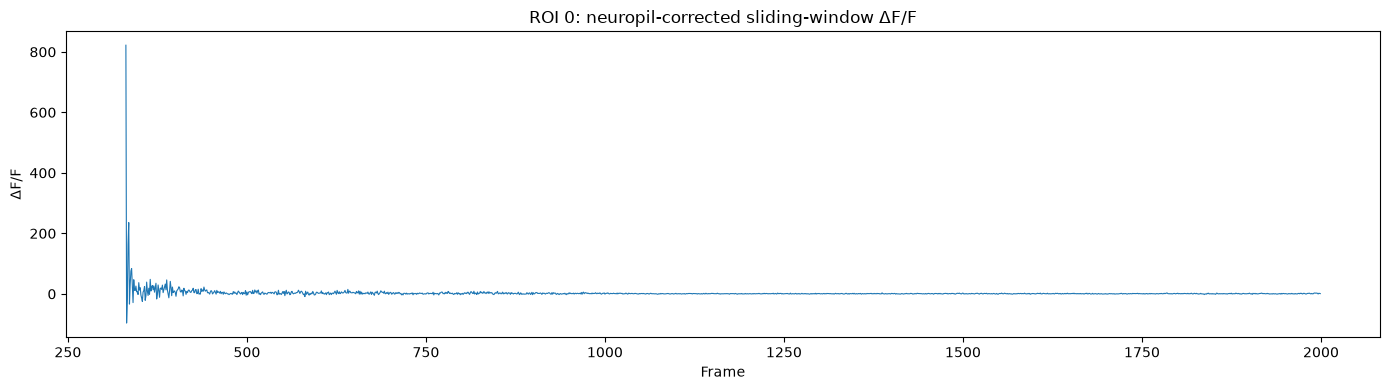

In [4]:
ROI_TO_PLOT = int(valid_roi_indices[0])
plt.figure(figsize=(14, 4))
plt.plot(dff[ROI_TO_PLOT, :2000], lw=0.8)
plt.xlabel('Frame')
plt.ylabel('ΔF/F')
plt.title(f'ROI {ROI_TO_PLOT}: neuropil-corrected sliding-window ΔF/F')
plt.tight_layout()
plt.show()

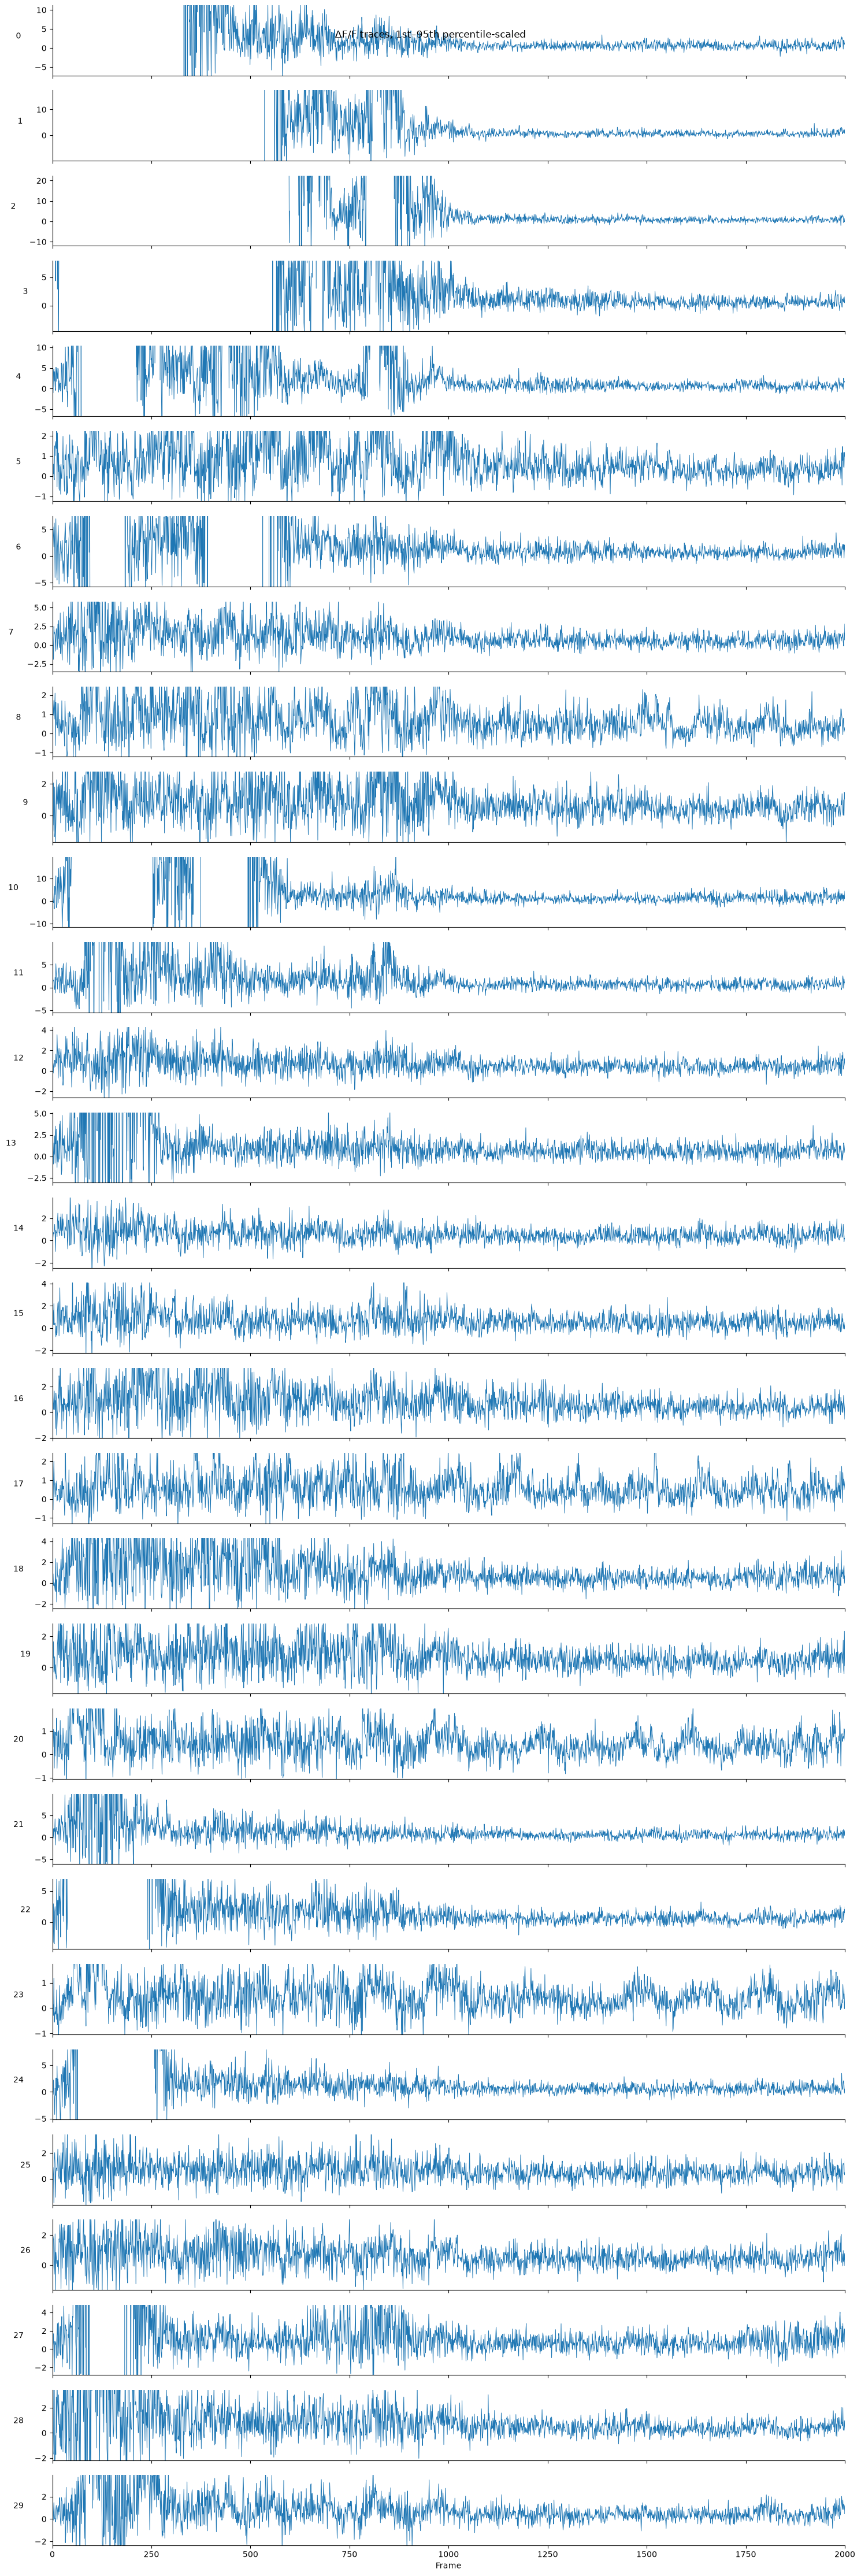

In [5]:
N_ROIS_TO_PLOT = 30
START_FRAME = 0
END_FRAME = 2000  # use None for the full recording
LOW_PCTL = 1
HIGH_PCTL = 95
rois_to_plot = valid_roi_indices[:N_ROIS_TO_PLOT]
fig, axes = plt.subplots(len(rois_to_plot), 1, figsize=(15, 1.5 * len(rois_to_plot)), sharex=True)
axes = np.atleast_1d(axes)
for ax, roi in zip(axes, rois_to_plot):
    trace = dff[roi]
    ax.plot(trace, lw=0.7)
    ymin, ymax = np.nanpercentile(trace, [LOW_PCTL, HIGH_PCTL])
    pad = 0.1 * (ymax - ymin) if ymax > ymin else 1.0
    ax.set_ylim(ymin - pad, ymax + pad)
    ax.set_ylabel(str(roi), rotation=0, labelpad=20)
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_xlim(START_FRAME, END_FRAME)
axes[-1].set_xlabel('Frame')
fig.suptitle('ΔF/F traces, 1st–95th percentile-scaled')
fig.tight_layout()
plt.show()

## Stacked traces in original ROI order

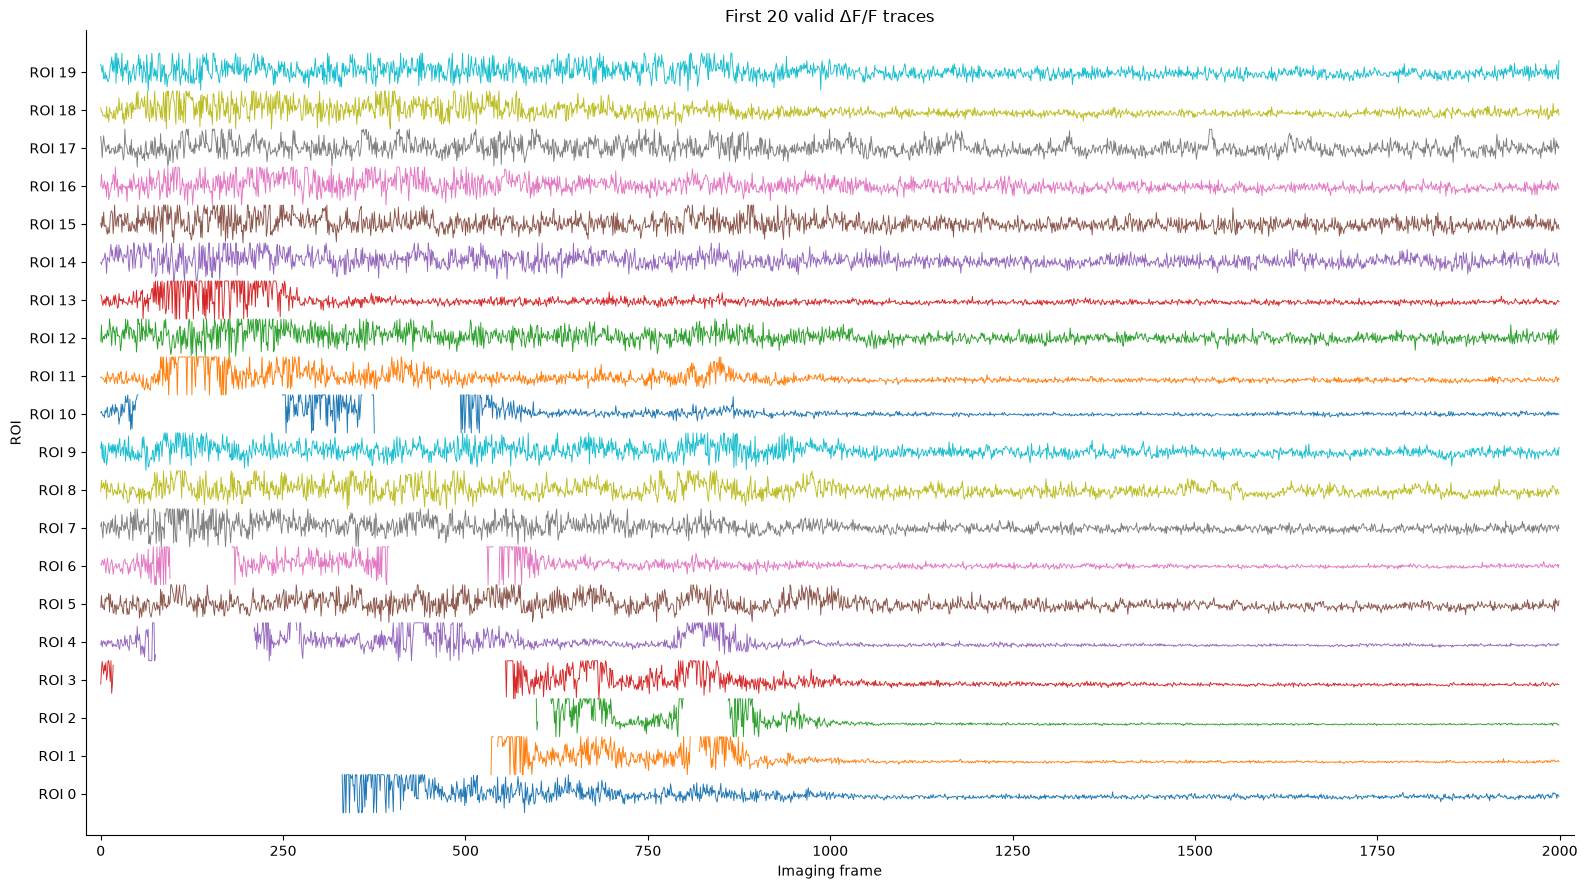

In [6]:
def plot_stacked_traces(traces, roi_indices, start_frame=0, end_frame=2000, low=1, high=95, spacing=1.5, title='Stacked traces'):
    roi_indices = np.asarray(roi_indices, dtype=int)
    frame_slice = slice(start_frame, end_frame)
    frames = np.arange(traces.shape[1])[frame_slice]
    offsets = np.arange(len(roi_indices)) * spacing
    colors = plt.cm.tab10(np.arange(len(roi_indices)) % 10)
    fig, ax = plt.subplots(figsize=(16, max(6, 0.45 * len(roi_indices))))
    for offset, color, roi in zip(offsets, colors, roi_indices):
        trace = np.asarray(traces[roi, frame_slice], dtype=float)
        lo, hi = np.nanpercentile(trace, [low, high])
        scale = hi - lo
        if not np.isfinite(scale) or scale <= 0:
            continue
        shown = np.clip((trace - lo) / scale, -0.25, 1.25)
        ax.plot(frames, shown + offset, color=color, lw=0.65)
    ax.set_yticks(offsets + 0.5, [f'ROI {roi}' for roi in roi_indices])
    ax.set(xlabel='Imaging frame', ylabel='ROI', title=title)
    ax.spines[['top', 'right']].set_visible(False)
    ax.margins(x=0.01, y=0.03)
    fig.tight_layout()
    plt.show()

N_STACKED_ROIS = 20
plot_stacked_traces(
    dff, valid_roi_indices[:N_STACKED_ROIS],
    title=f'First {min(N_STACKED_ROIS, len(valid_roi_indices))} valid ΔF/F traces'
)

## Detect and interpolate population-wide artifacts

In [7]:
ARTIFACT_DETECTION_METHOD = 'derivative_z'  # or 'percentile'
CELL_SPIKE_THRESHOLD = 6.0
LOW_ARTIFACT_PERCENTILE = 1.0
HIGH_ARTIFACT_PERCENTILE = 99.0
MIN_FRACTION_CELLS = 0.25
ARTIFACT_PADDING_FRAMES = 1

def detect_global_spike_frames(traces, method='derivative_z', cell_spike_threshold=6, low_percentile=1, high_percentile=99, min_fraction_cells=0.25, padding_frames=1):
    traces = np.asarray(traces, dtype=np.float64)
    valid_cells = np.any(np.isfinite(traces), axis=1)
    derivative = np.diff(traces, axis=1, prepend=traces[:, :1])
    med = np.nanmedian(derivative, axis=1, keepdims=True)
    mad = np.nanmedian(np.abs(derivative - med), axis=1, keepdims=True)
    scale = 1.4826 * mad
    scale[scale < 1e-12] = np.nan
    derivative_z = (derivative - med) / scale
    if method == 'derivative_z':
        cells_spiking = np.abs(derivative_z) >= cell_spike_threshold
    elif method == 'percentile':
        lo = np.nanpercentile(traces, low_percentile, axis=1, keepdims=True)
        hi = np.nanpercentile(traces, high_percentile, axis=1, keepdims=True)
        cells_spiking = (traces < lo) | (traces > hi)
    else:
        raise ValueError("method must be 'derivative_z' or 'percentile'")
    fraction_spiking = np.mean(cells_spiking[valid_cells], axis=0)
    artifact_frames = fraction_spiking >= min_fraction_cells
    if padding_frames > 0:
        artifact_frames = binary_dilation(artifact_frames, structure=np.ones(2 * padding_frames + 1, bool))
    return artifact_frames, fraction_spiking, derivative_z

def interpolate_artifact_frames(traces, artifact_frames):
    traces = np.asarray(traces, dtype=np.float64)
    corrected = traces.copy()
    frames = np.arange(traces.shape[1])
    for roi in range(traces.shape[0]):
        valid = ~artifact_frames & np.isfinite(traces[roi])
        if valid.sum() >= 2:
            corrected[roi, artifact_frames] = np.interp(frames[artifact_frames], frames[valid], traces[roi, valid])
    return corrected.astype(np.float32)

artifact_frames, fraction_spiking, derivative_z = detect_global_spike_frames(
    dff, method=ARTIFACT_DETECTION_METHOD, cell_spike_threshold=CELL_SPIKE_THRESHOLD,
    low_percentile=LOW_ARTIFACT_PERCENTILE, high_percentile=HIGH_ARTIFACT_PERCENTILE,
    min_fraction_cells=MIN_FRACTION_CELLS, padding_frames=ARTIFACT_PADDING_FRAMES,
)
dff_corrected = interpolate_artifact_frames(dff, artifact_frames)
np.save(OUTPUT_DIR / 'dff_corrected.npy', dff_corrected)
np.save(OUTPUT_DIR / 'artifact_frames.npy', artifact_frames)
print(f'Detected {artifact_frames.sum()} / {len(artifact_frames)} artifact frames ({100 * artifact_frames.mean():.3f}%)')

Detected 0 / 8503 artifact frames (0.000%)


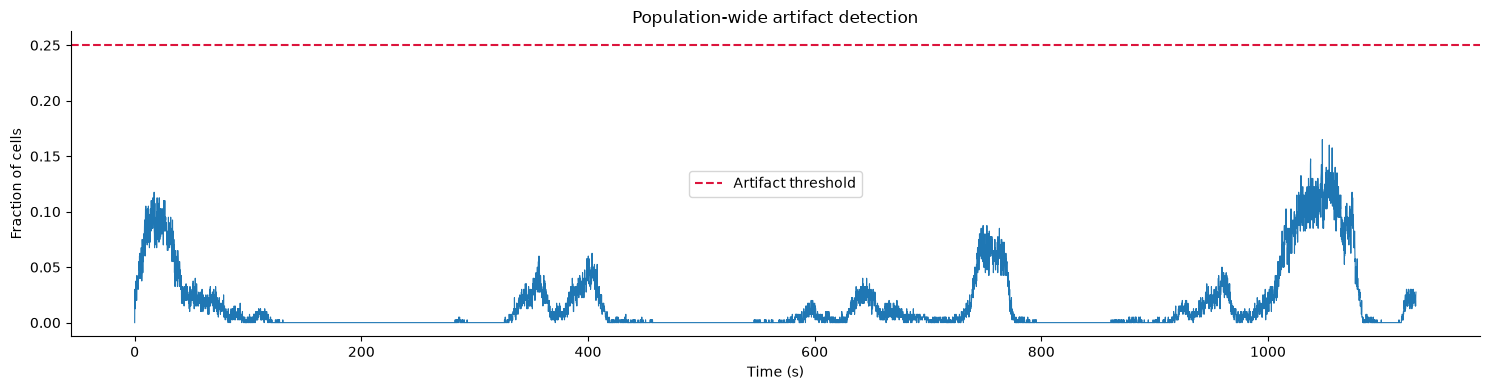

In [8]:
x = np.arange(dff.shape[1]) / FRAME_RATE_HZ
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(x, fraction_spiking, lw=0.8)
ax.axhline(MIN_FRACTION_CELLS, color='crimson', ls='--', label='Artifact threshold')
idx = np.flatnonzero(artifact_frames)
if len(idx):
    ax.scatter(x[idx], fraction_spiking[idx], s=8, label='Removed frames')
ax.set(xlabel='Time (s)', ylabel='Fraction of cells', title='Population-wide artifact detection')
ax.spines[['top', 'right']].set_visible(False)
ax.legend()
fig.tight_layout()
plt.show()

## Corrected traces in original ROI order (no responsiveness ranking)

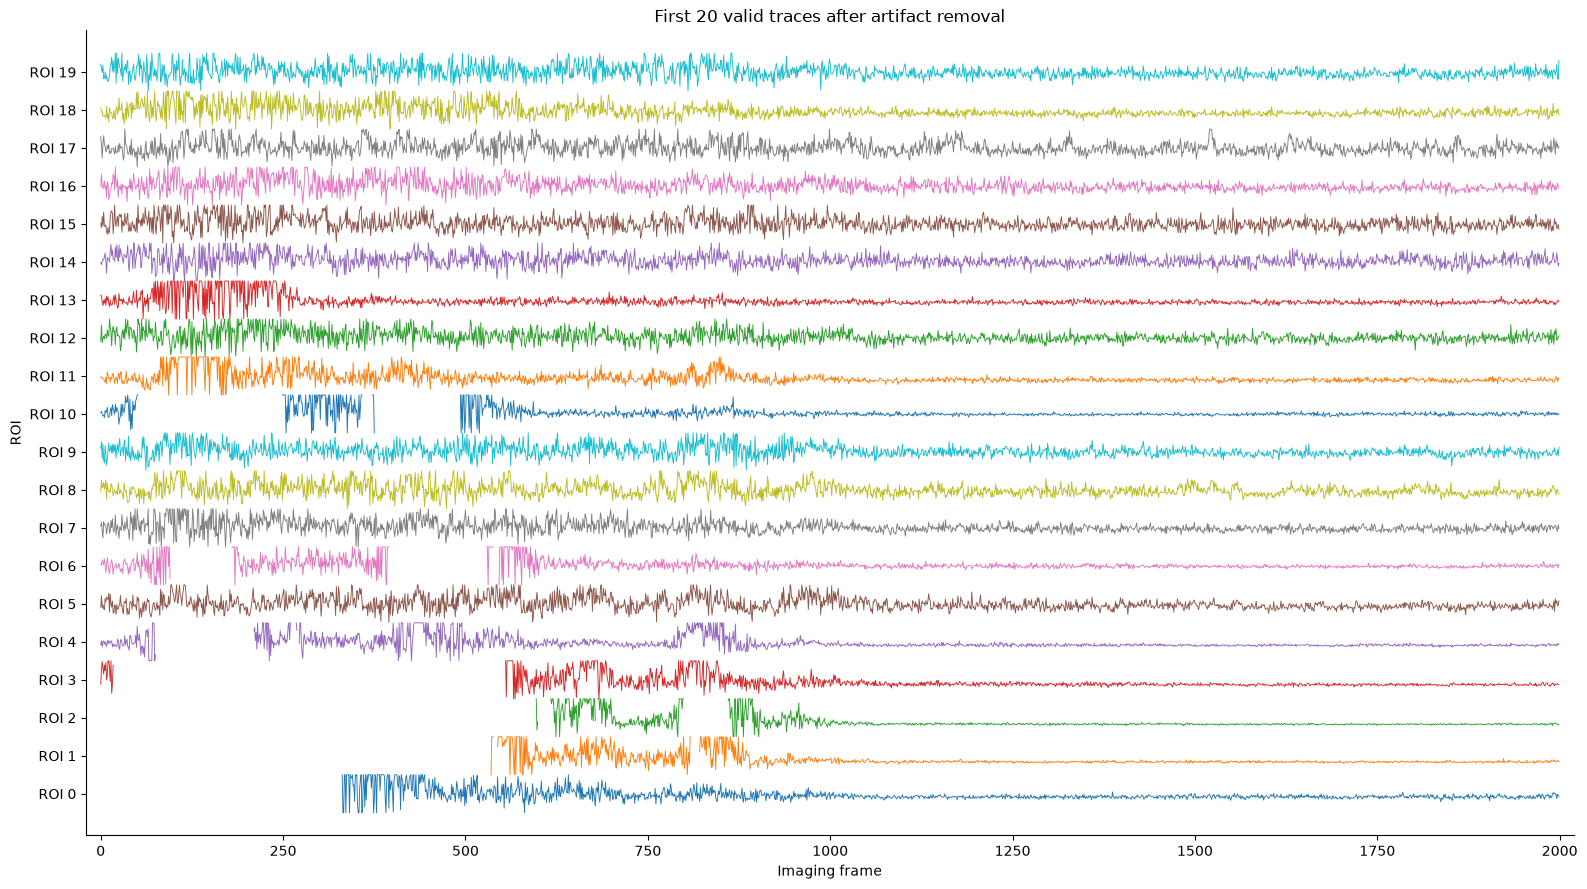

In [9]:
corrected_valid_rois = np.flatnonzero(np.any(np.isfinite(dff_corrected), axis=1))
plot_stacked_traces(
    dff_corrected, corrected_valid_rois[:N_STACKED_ROIS],
    title=f'First {min(N_STACKED_ROIS, len(corrected_valid_rois))} valid traces after artifact removal'
)

## Optional: most responsive corrected cells

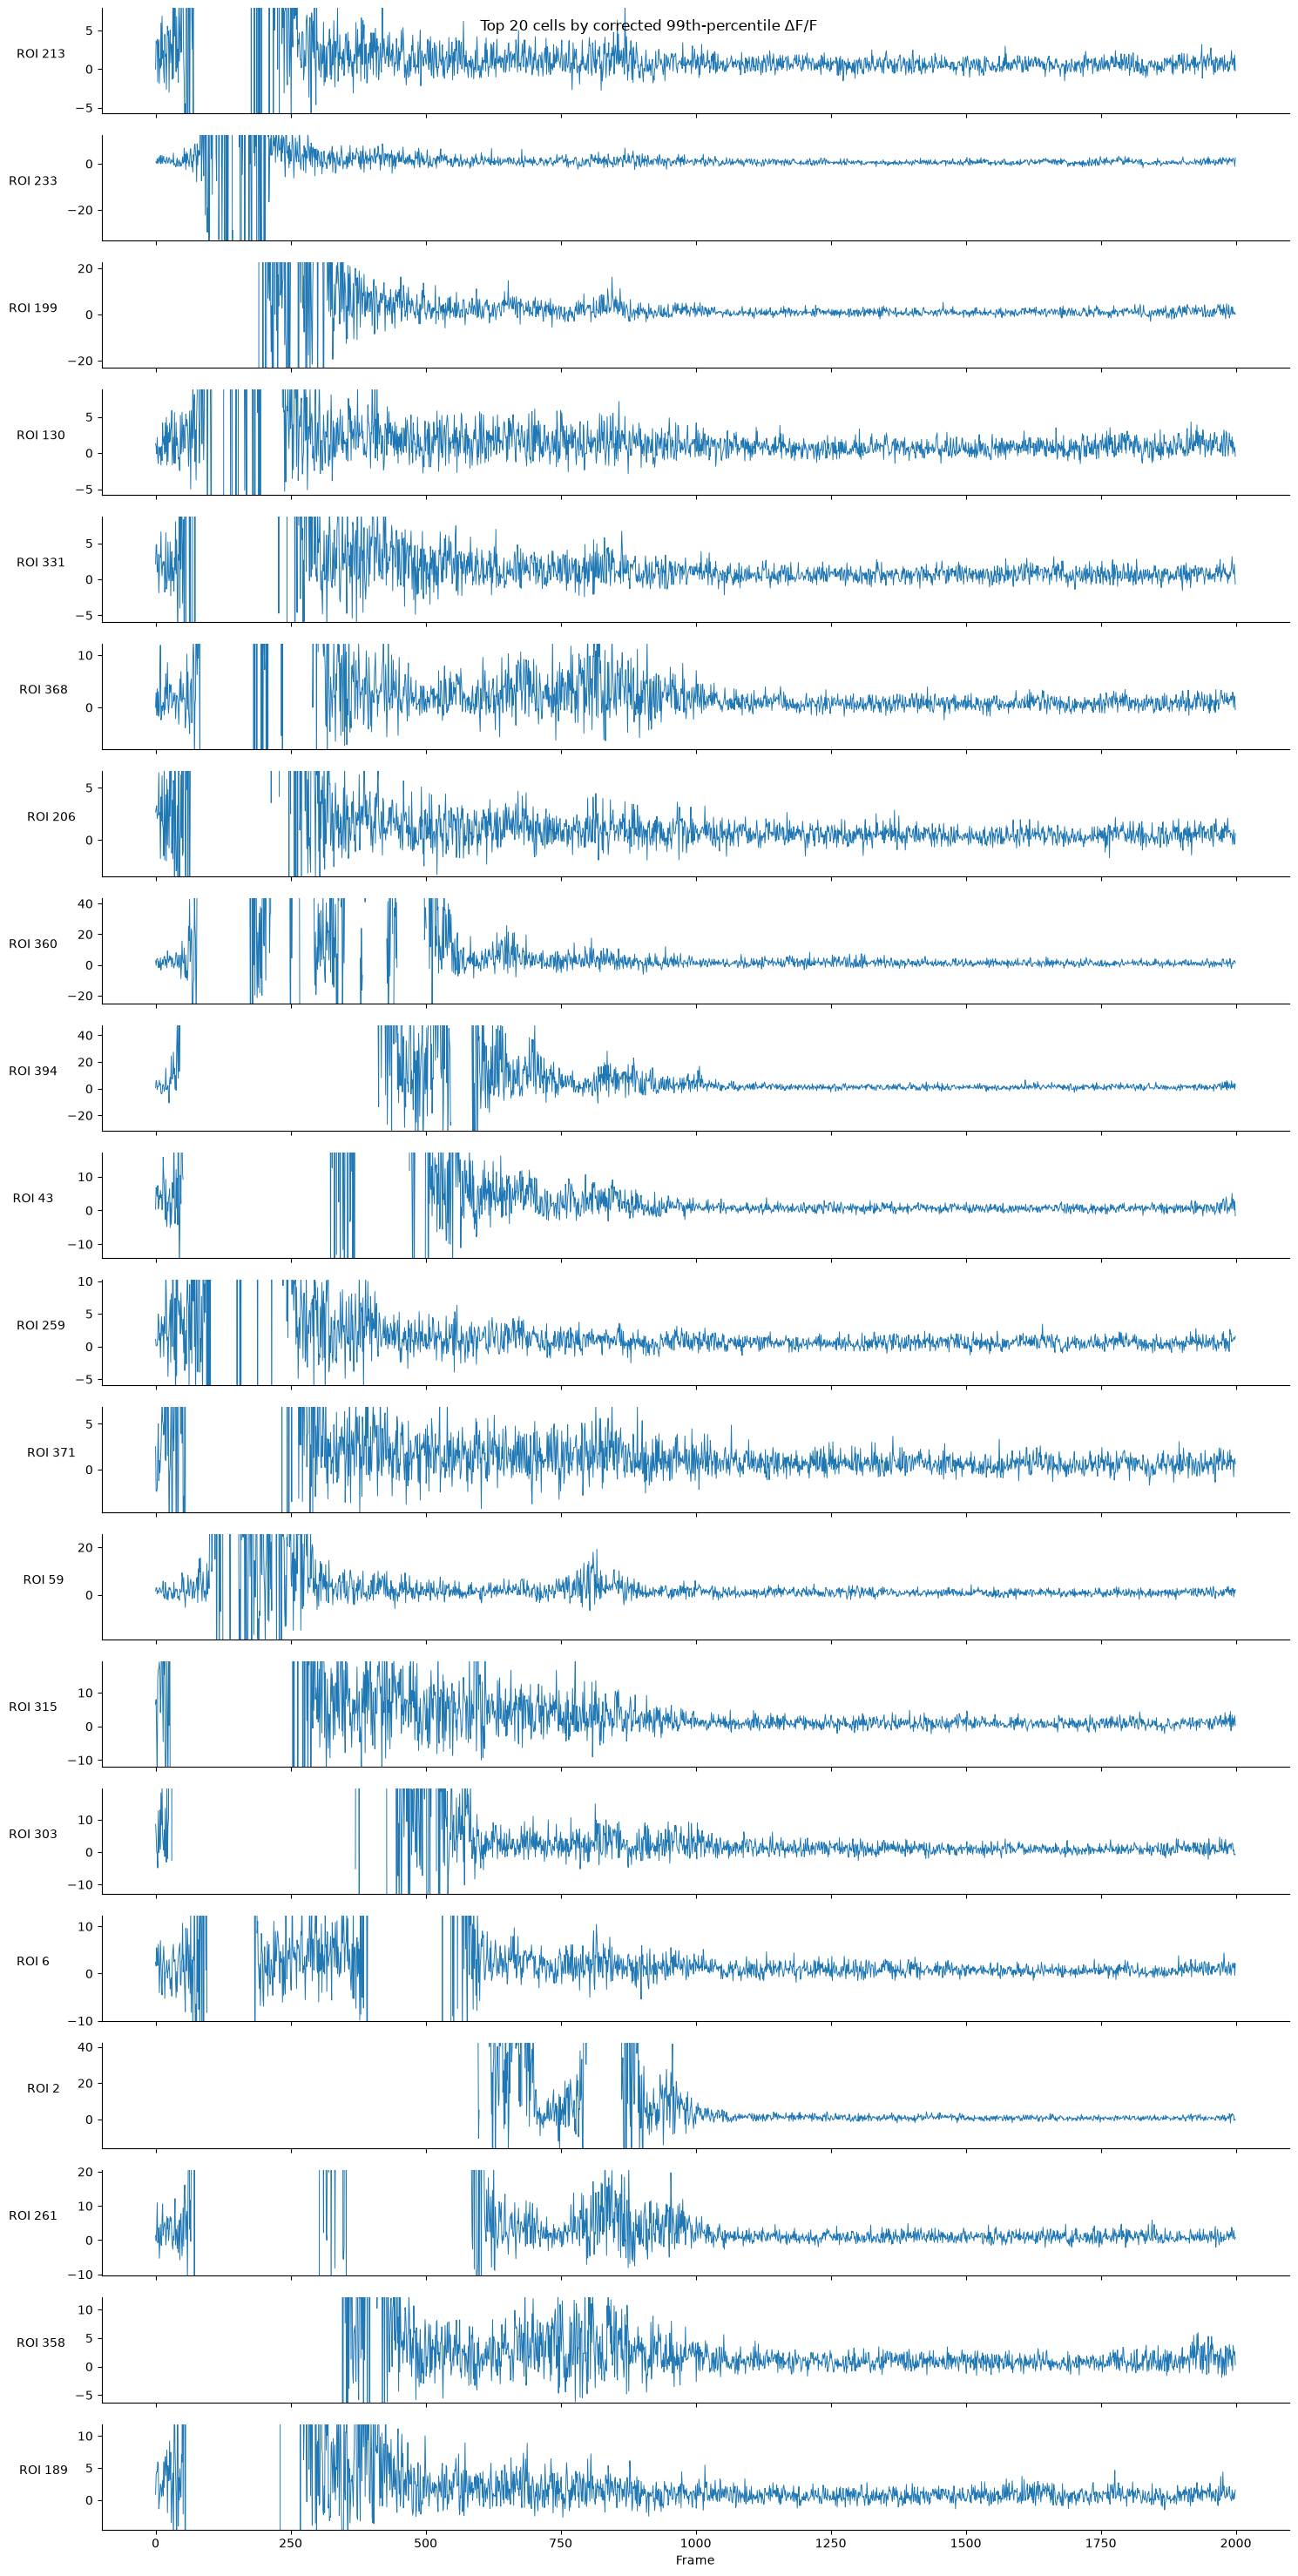

In [10]:
N_RESPONSIVE_ROIS = 20
RESPONSE_PERCENTILE = 99
response_score = np.full(dff_corrected.shape[0], np.nan)
response_score[corrected_valid_rois] = np.nanpercentile(dff_corrected[corrected_valid_rois, :2000], RESPONSE_PERCENTILE, axis=1)
top_rois = corrected_valid_rois[np.argsort(response_score[corrected_valid_rois])[::-1]][:N_RESPONSIVE_ROIS]
fig, axes = plt.subplots(len(top_rois), 1, figsize=(15, 1.5 * len(top_rois)), sharex=True)
axes = np.atleast_1d(axes)
for ax, roi in zip(axes, top_rois):
    trace = dff_corrected[roi, :2000]
    ax.plot(trace, lw=0.7)
    lo, hi = np.nanpercentile(trace, [LOW_PCTL, HIGH_PCTL])
    pad = 0.1 * (hi - lo) if hi > lo else 1.0
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_ylabel(f'ROI {roi}', rotation=0, labelpad=28)
    ax.spines[['top', 'right']].set_visible(False)
axes[-1].set_xlabel('Frame')
fig.suptitle(f'Top {len(top_rois)} cells by corrected {RESPONSE_PERCENTILE}th-percentile ΔF/F')
fig.tight_layout()
plt.show()

## Select an ROI on the mean image
Select any ROI to highlight its exact mask and inspect its original sliding-baseline ΔF/F for the first 2,000 frames, before artifact interpolation.


In [11]:
import ipywidgets as widgets
from IPython.display import display, clear_output

image_key = next((key for key in ('meanImg', 'meanImgE') if key in ops), None)
if image_key is None:
    raise KeyError("No meanImg or meanImgE found in ops.npy.")
mean_image = np.asarray(ops[image_key])
if mean_image.ndim != 2 or not np.isfinite(mean_image).any():
    raise ValueError('Expected a 2D mean image with finite values.')
vmin, vmax = np.percentile(mean_image[np.isfinite(mean_image)], [1, 99])
if vmax <= vmin:
    vmax = vmin + 1
rank_lookup = {}
options = []
for roi in range(len(stat)):
    label = f'ROI {roi}'
    if roi in rank_lookup:
        label += f' — top 30, rank {rank_lookup[roi]}'
    label += ' — cell' if iscell[roi, 0] == 1 else ' — not classified as cell'
    options.append((label, roi))
roi_dropdown = widgets.Dropdown(options=options, value=int(valid_roi_indices[0]),
                               description='ROI:', layout=widgets.Layout(width='550px'))
roi_output = widgets.Output()

def show_selected_roi(change=None):
    roi = roi_dropdown.value
    ypix = np.asarray(stat[roi]['ypix'], dtype=int)
    xpix = np.asarray(stat[roi]['xpix'], dtype=int)
    if (np.any(ypix < 0) or np.any(ypix >= mean_image.shape[0])
            or np.any(xpix < 0) or np.any(xpix >= mean_image.shape[1])):
        raise ValueError('ROI coordinates do not match the mean-image dimensions.')
    overlay = np.zeros((*mean_image.shape, 4), dtype=float)
    overlay[ypix, xpix] = [1, 0.15, 0, 0.7]
    with roi_output:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 2, figsize=(15, 5),
                                 gridspec_kw={'width_ratios': [1, 2]},
                                 constrained_layout=True)
        axes[0].imshow(mean_image, cmap='gray', vmin=vmin, vmax=vmax,
                       origin='upper', interpolation='nearest')
        axes[0].imshow(overlay, origin='upper', interpolation='nearest')
        axes[0].set(title=f'{image_key}: ROI {roi} highlighted', xlabel='x pixel', ylabel='y pixel')
        trace = dff[roi, :2000]
        axes[1].plot(trace, lw=0.7)
        axes[1].set(title=f'ROI {roi} — first {len(trace)} frames', xlabel='Frame', ylabel='ΔF/F')
        axes[1].spines['top'].set_visible(False)
        axes[1].spines['right'].set_visible(False)
        if not np.isfinite(trace).any():
            axes[1].text(0.5, 0.5, 'Invalid baseline: ΔF/F unavailable',
                         transform=axes[1].transAxes, ha='center')
        plt.show()

roi_dropdown.observe(show_selected_roi, names='value')
display(roi_dropdown, roi_output)
show_selected_roi()


Dropdown(description='ROI:', layout=Layout(width='550px'), options=(('ROI 0 — cell', 0), ('ROI 1 — cell', 1), …

Output()